# 🛠️ **IMPORTS**: Bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# 💻 **CÓDIGOS**: Implementação

In [7]:
file_censo = '../data/censo2022/br_ibge_censo_2022_alfabetizacao_grupo_idade_sexo_raca.xlsx'
df = pd.read_excel(file_censo)

In [8]:
df_totais = df.groupby(['sexo', 'alfabetizacao'])['populacao'].sum().unstack()

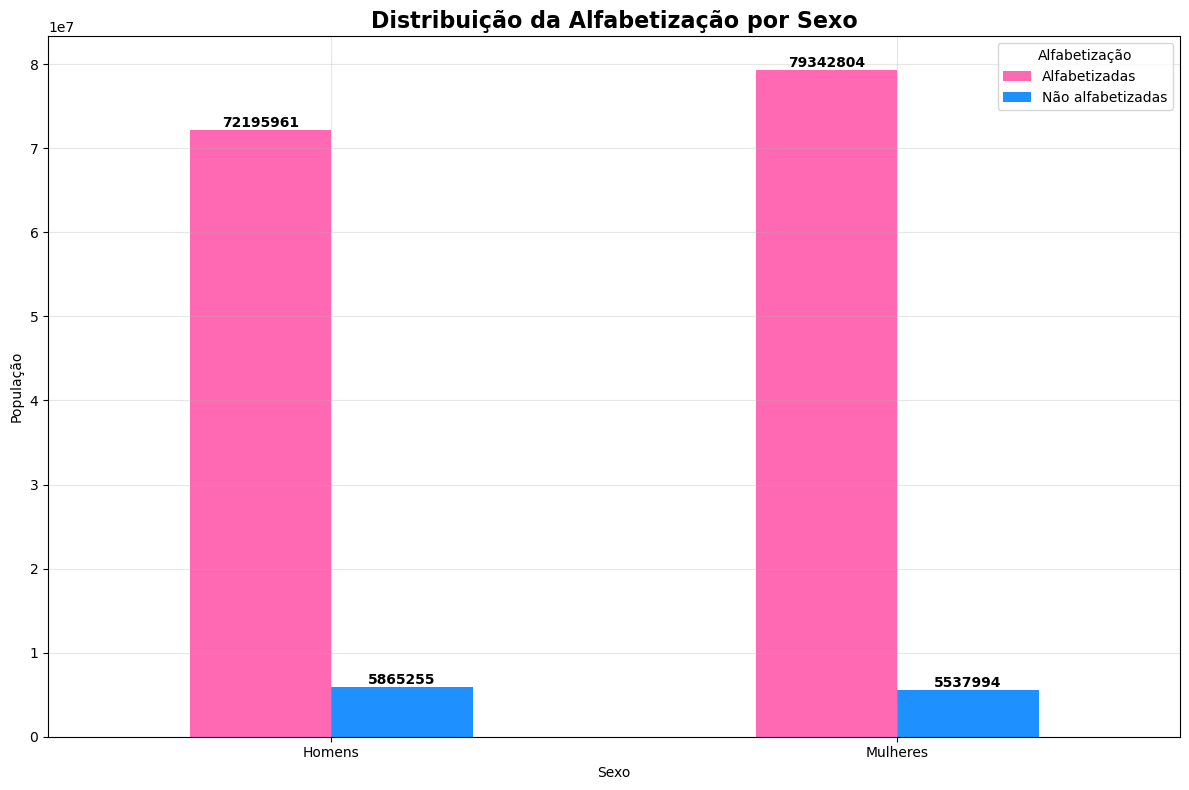

In [11]:
ax = df_totais.plot(kind='bar', figsize=(12, 8), color=['#FF69B4', '#1E90FF'])
plt.title('Distribuição da Alfabetização por Sexo', fontsize=16, fontweight='bold')
plt.xlabel('Sexo')
plt.ylabel('População')
plt.xticks(rotation=0)
plt.legend(title='Alfabetização')
plt.grid(True, alpha=0.3)

# Adicionar valores nas barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
df_totais_raca = df.groupby(['cor_raca', 'alfabetizacao'])['populacao'].sum().unstack()

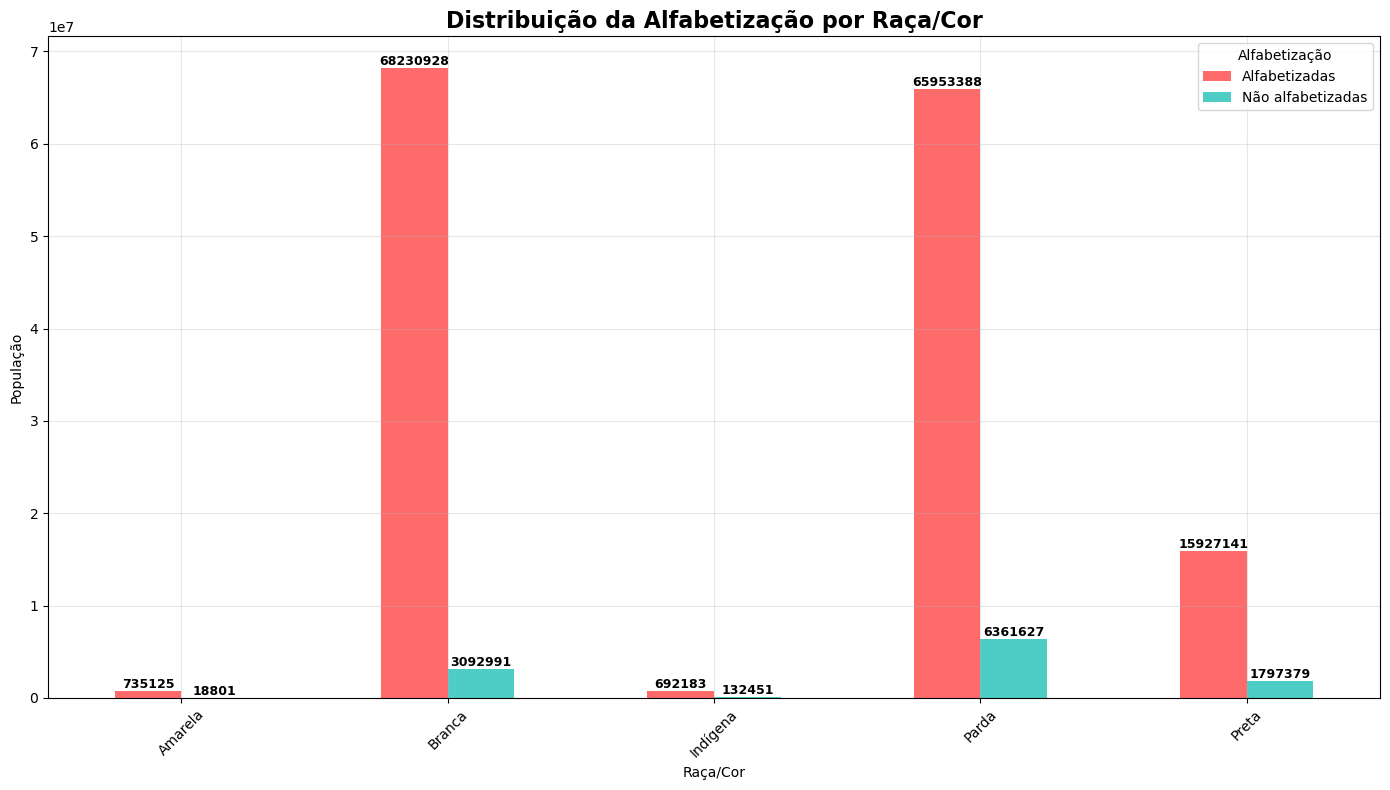

In [ ]:
ax = df_totais_raca.plot(kind='bar', figsize=(14, 8), color=['#FF6B6B', '#4ECDC4'])
plt.title('Distribuição da Alfabetização por Raça/Cor', fontsize=16, fontweight='bold')
plt.xlabel('Raça/Cor')
plt.ylabel('População')
plt.xticks(rotation=45)
plt.legend(title='Alfabetização')
plt.grid(True, alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

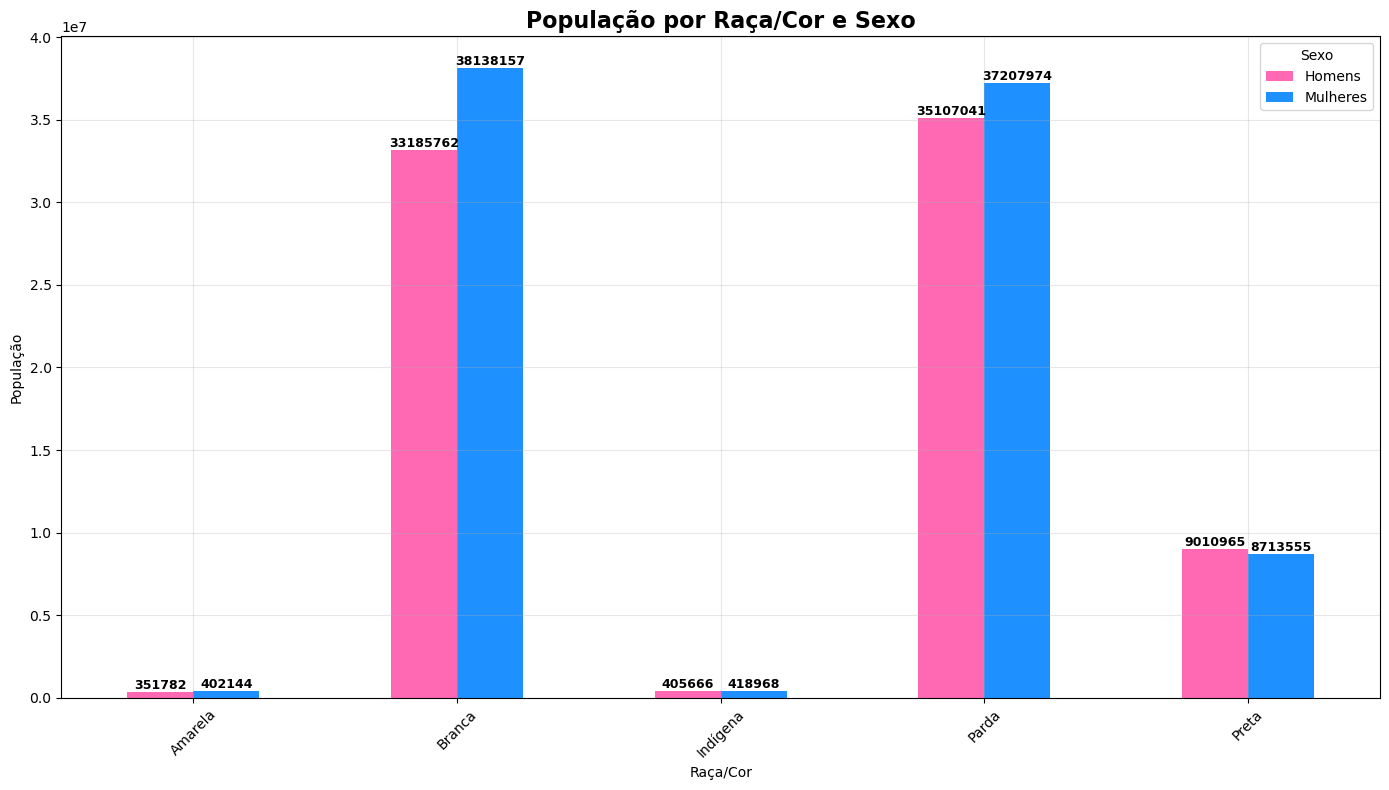

In [15]:
df_totais_raca_sexo = df.groupby(['cor_raca', 'sexo'])['populacao'].sum().unstack()

ax = df_totais_raca_sexo.plot(kind='bar', figsize=(14, 8), color=['#FF69B4', '#1E90FF'])
plt.title('População por Raça/Cor e Sexo', fontsize=16, fontweight='bold')
plt.xlabel('Raça/Cor')
plt.ylabel('População')
plt.xticks(rotation=45)
plt.legend(title='Sexo')
plt.grid(True, alpha=0.3)

# Adicionar valores nas barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

Categorias de alfabetização: ['Homens', 'Mulheres']
Sexos encontrados: ['Alfabetizadas', 'Não alfabetizadas']


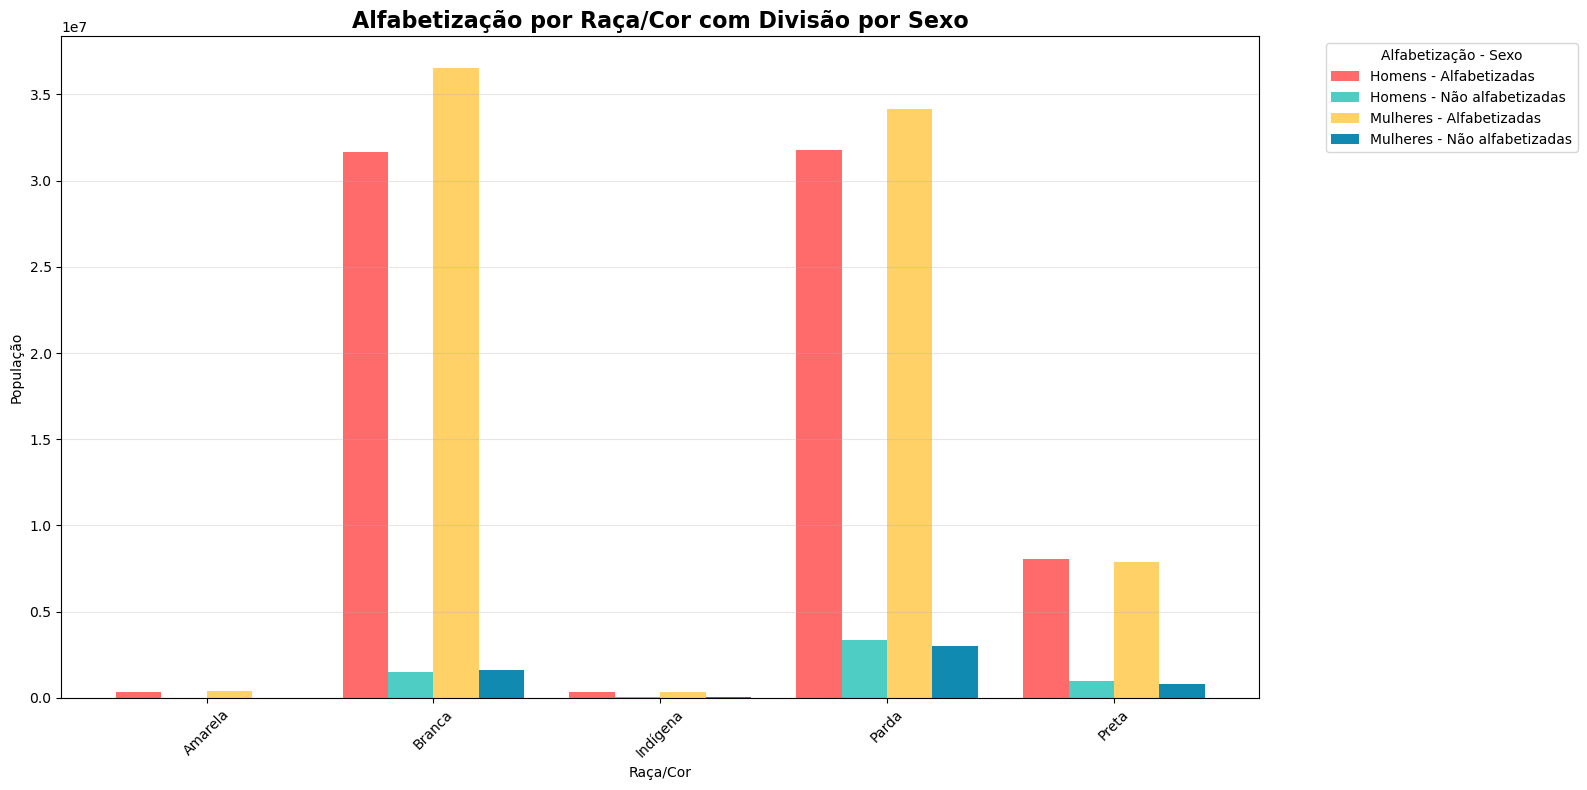

In [26]:
df_agrupado = df.groupby(['cor_raca', 'alfabetizacao', 'sexo'])['populacao'].sum().unstack().unstack()

# Obter os nomes corretos automaticamente
racas = df_agrupado.index
categorias = df_agrupado.columns.get_level_values(0).unique().tolist()
sexos = df_agrupado.columns.get_level_values(1).unique().tolist()

print(f"Categorias de alfabetização: {categorias}")
print(f"Sexos encontrados: {sexos}")

fig, ax = plt.subplots(figsize=(16, 8))

x = np.arange(len(racas))
largura = 0.2

# DEFINIR 4 CORES EXPLÍCITAS E DIFERENTES
cores = [
    '#FF6B6B',  # Vermelho - Analfabeto Feminino
    '#4ECDC4',  # Turquesa - Analfabeto Masculino  
    '#FFD166',  # Amarelo - Alfabetizado Feminino
    '#118AB2'   # Azul - Alfabetizado Masculino
]

# Para cada combinação de alfabetização e sexo
bar_index = 0
for i, categoria in enumerate(categorias):
    for j, sexo in enumerate(sexos):
        valores = [df_agrupado.loc[raca, (categoria, sexo)] for raca in racas]
        posicao = x + (i * len(sexos) + j) * largura
        
        ax.bar(posicao, valores, largura, 
               label=f'{categoria} - {sexo}',
               color=cores[bar_index])
        bar_index += 1

ax.set_title('Alfabetização por Raça/Cor com Divisão por Sexo', fontsize=16, fontweight='bold')
ax.set_xlabel('Raça/Cor')
ax.set_ylabel('População')
ax.set_xticks(x + largura * 1.5)
ax.set_xticklabels(racas, rotation=45)
ax.legend(title='Alfabetização - Sexo', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()